In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/ID_to_Image_Mapping.csv
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/train.csv
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00011124_000.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00030039_008.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00017257_001.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00013977_005.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00007444_003.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00008727_009.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00020845_002.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00000398_003.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00012288_000.png
/kaggle/input/m-2-big-data-dlia-project-2025-clean-dataset/test/00017514_008.png
/kaggle/input/m-2-big-data-dlia-projec

In [2]:
!pip -q install ultralytics

import os, shutil
import pandas as pd
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm import tqdm

from ultralytics import YOLO


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.2 MB/s eta 0:00:00a 0:00:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
import pandas as pd

train_df = pd.read_csv("../input/m-2-big-data-dlia-project-2025-clean-dataset/train.csv")

print("Columns:")
print(train_df.columns)

print("\nSample rows:")
train_df.head()


Columns:
Index(['image_id', 'label', 'x_min', 'y_min', 'x_max', 'y_max'], dtype='object')

Sample rows:


,image_id,label,x_min,y_min,x_max,y_max
0,00000032_037.png,Infiltrate,339.166138,119.195767,511.458201,470.281481
1,00000072_000.png,Atelectasis,356.503704,567.805291,484.368254,650.158730
2,00000147_001.png,Atelectasis,617.650794,599.229630,718.425397,779.106878
3,00000149_006.png,Atelectasis,603.661017,460.239556,853.152542,550.273454
4,00000181_061.png,Atelectasis,209.898305,568.714132,423.593220,823.629386


In [4]:
print(train_df[["x_min","y_min","x_max","y_max"]].describe())

            x_min       y_min        x_max        y_max
count  814.000000  814.000000   814.000000   814.000000
mean   401.096881  404.269757   653.424293   656.898293
std    226.454609  167.196326   236.571068   166.287646
min      5.417989   12.837934   131.413333    34.455712
25%    201.650794  291.798690   417.422222   574.806997
50%    342.159577  415.341718   765.155556   685.049232
75%    611.555556  521.210582   851.957514   769.369130
max    905.887831  876.980783  1012.080423  1022.046823


In [5]:
assert (train_df["x_max"] > train_df["x_min"]).all()
assert (train_df["y_max"] > train_df["y_min"]).all()
print("✅ All boxes have valid geometry")

✅ All boxes have valid geometry


In [6]:
from PIL import Image
import os

IMAGES_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/train"

sizes = set()
for img_name in train_df["image_id"].unique()[:20]:
    img = Image.open(os.path.join(IMAGES_DIR, img_name))
    sizes.add(img.size)

print("Image sizes:", sizes)

Image sizes: {(1024, 1024)}


In [7]:
# train_df must contain:
# ['image_id','label','x_min','y_min','x_max','y_max']

print(train_df.columns)
print("n images:", train_df["image_id"].nunique())
print("labels:", sorted(train_df["label"].unique()))


Index(['image_id', 'label', 'x_min', 'y_min', 'x_max', 'y_max'], dtype='object')
n images: 710
labels: ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltrate', 'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax']


32.5079365079365 359.754497354497 306.6582010582015 660.9947089947091


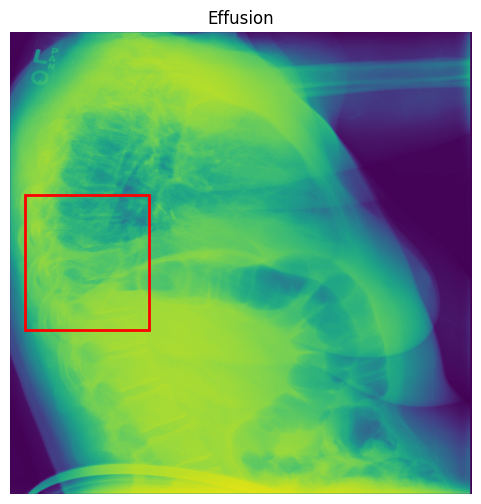

In [8]:
import matplotlib.pyplot as plt
import random

row = train_df.sample(1).iloc[0]

img = Image.open(os.path.join(IMAGES_DIR, row["image_id"]))
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")

x1, y1, x2, y2 = row["x_min"], row["y_min"], row["x_max"], row["y_max"]
print(x1, y1, x2, y2)
plt.gca().add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)


plt.title(row["label"])
plt.show()

In [9]:
print(train_df["label"].value_counts())


label
Atelectasis     145
Effusion        130
Cardiomegaly    112
Infiltrate      106
Pneumonia        98
Pneumothorax     86
Mass             77
Nodule           60
Name: count, dtype: int64


In [10]:
labels = sorted(train_df["label"].unique())
label2id = {l:i for i,l in enumerate(labels)}
id2label = {i:l for l,i in label2id.items()}

NUM_CLASSES = len(labels)
print("NUM_CLASSES:", NUM_CLASSES)
print(label2id)


NUM_CLASSES: 8
{'Atelectasis': 0, 'Cardiomegaly': 1, 'Effusion': 2, 'Infiltrate': 3, 'Mass': 4, 'Nodule': 5, 'Pneumonia': 6, 'Pneumothorax': 7}


In [11]:
IMAGES_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/train"

YOLO_ROOT = "yolo8cls"
IMG_TRAIN = f"{YOLO_ROOT}/images/train"
IMG_VAL   = f"{YOLO_ROOT}/images/val"
LBL_TRAIN = f"{YOLO_ROOT}/labels/train"
LBL_VAL   = f"{YOLO_ROOT}/labels/val"

for p in [IMG_TRAIN, IMG_VAL, LBL_TRAIN, LBL_VAL]:
    os.makedirs(p, exist_ok=True)

# split by image_id (important: not by bbox row)
image_ids = train_df["image_id"].unique()
train_ids, val_ids = train_test_split(image_ids, test_size=0.2, random_state=42)

train_ids = set(train_ids)
val_ids   = set(val_ids)

def write_yolo_labels(image_id, subset):
    img_path = os.path.join(IMAGES_DIR, image_id)
    img = Image.open(img_path)
    W, H = img.size

    rows = train_df[train_df["image_id"] == image_id]

    img_out = IMG_TRAIN if subset == "train" else IMG_VAL
    lbl_out = LBL_TRAIN if subset == "train" else LBL_VAL

    # copy image
    shutil.copy(img_path, os.path.join(img_out, image_id))

    # write label file
    label_file = os.path.join(lbl_out, image_id.replace(".png", ".txt"))
    with open(label_file, "w") as f:
        for _, r in rows.iterrows():
            x1, y1, x2, y2 = float(r["x_min"]), float(r["y_min"]), float(r["x_max"]), float(r["y_max"])
            cls_id = label2id[r["label"]]

            # xyxy -> normalized xywh
            xc = ((x1 + x2) / 2.0) / W
            yc = ((y1 + y2) / 2.0) / H
            bw = (x2 - x1) / W
            bh = (y2 - y1) / H

            # clamp for safety
            xc = min(max(xc, 0.0), 1.0)
            yc = min(max(yc, 0.0), 1.0)
            bw = min(max(bw, 0.0), 1.0)
            bh = min(max(bh, 0.0), 1.0)

            # skip degenerate boxes
            if bw <= 0 or bh <= 0:
                continue

            f.write(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

print("Converting YOLO train...")
for img_id in tqdm(list(train_ids)[:]):  # all
    write_yolo_labels(img_id, "train")

print("Converting YOLO val...")
for img_id in tqdm(list(val_ids)[:]):    # all
    write_yolo_labels(img_id, "val")

print("✅ YOLO multi-class dataset ready")

Converting YOLO train...


100%|██████████| 568/568 [00:05<00:00, 96.31it/s] 


Converting YOLO val...


100%|██████████| 142/142 [00:01<00:00, 123.74it/s]

✅ YOLO multi-class dataset ready


In [12]:
yaml_path = f"{YOLO_ROOT}.yaml"

with open(yaml_path, "w") as f:
    f.write(f"path: {YOLO_ROOT}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write(f"nc: {NUM_CLASSES}\n")
    f.write("names:\n")
    for i in range(NUM_CLASSES):
        f.write(f"  {i}: {id2label[i]}\n")

print("✅ YAML written:", yaml_path)
print(open(yaml_path).read())


✅ YAML written: yolo8cls.yaml
path: yolo8cls
train: images/train
val: images/val
nc: 8
names:
  0: Atelectasis
  1: Cardiomegaly
  2: Effusion
  3: Infiltrate
  4: Mass
  5: Nodule
  6: Pneumonia
  7: Pneumothorax



In [13]:
from ultralytics import YOLO

model = YOLO("yolov8l.pt")  # ⬅️ IMPORTANT

model.train(
    data=yaml_path,
    epochs=120,
    imgsz=1024,           # ⬅️ crucial pour radiographies
    batch=4,              # GPU P100 ok
    lr0=0.003,
    cos_lr=True,
    box=7.5,
    cls=1.0,              # ⬅️ IMPORTANT (pas 0.0)
    patience=20,
    mosaic=0.2,
    mixup=0.0,
    device=0
)


Ultralytics 8.4.14 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=1.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=yolo8cls.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=120, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8l.pt, momentum=0.937, mosaic=0.2, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, perspective=0.0, pl

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e660c378440>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [14]:
!pip install -q ensemble-boxes

In [15]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion

# --------------------------------------------------
# CONFIG
# --------------------------------------------------
TEST_IMG_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/test"
mapping_df = pd.read_csv(
    "../input/m-2-big-data-dlia-project-2025-clean-dataset/ID_to_Image_Mapping.csv"
)

image_to_ID = dict(zip(mapping_df["image_id"], mapping_df["ID"]))

CONF_TTA = 0.01
IOU_WBF = 0.5

# --------------------------------------------------
# LOAD YOLO
# --------------------------------------------------
best_path = "runs/detect/train/weights/best.pt"
yolo = YOLO(best_path)

# --------------------------------------------------
# WBF helper
# --------------------------------------------------
def apply_wbf(boxes, scores, labels, W, H):
    if len(boxes) == 0:
        return []

    boxes_n = [[
        [b[0]/W, b[1]/H, b[2]/W, b[3]/H] for b in boxes
    ]]
    scores_n = [scores]
    labels_n = [labels]

    fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
        boxes_n,
        scores_n,
        labels_n,
        iou_thr=IOU_WBF,
        skip_box_thr=0.001
    )

    final = []
    for b,s,l in zip(fused_boxes, fused_scores, fused_labels):
        final.append((
            b[0]*W, b[1]*H, b[2]*W, b[3]*H,
            float(s),
            int(l)
        ))
    return final

# --------------------------------------------------
# TTA prediction
# --------------------------------------------------
def predict_tta(yolo, img_path):
    preds = []

    # normal
    r1 = yolo.predict(
        img_path, imgsz=1024, conf=CONF_TTA, device=0, verbose=False
    )[0]

    # horizontal flip
    r2 = yolo.predict(
        img_path, imgsz=1024, conf=CONF_TTA, augment=True, device=0, verbose=False
    )[0]

    for r in [r1, r2]:
        if r.boxes is None:
            continue
        for b, s, c in zip(
            r.boxes.xyxy.cpu().numpy(),
            r.boxes.conf.cpu().numpy(),
            r.boxes.cls.cpu().numpy().astype(int)
        ):
            preds.append((b, float(s), int(c)))

    return preds

# --------------------------------------------------
# INFERENCE LOOP
# --------------------------------------------------
rows = []

for image_id in sorted(os.listdir(TEST_IMG_DIR)):
    if image_id not in image_to_ID:
        continue

    ID = int(image_to_ID[image_id])
    img_path = os.path.join(TEST_IMG_DIR, image_id)

    img = Image.open(img_path).convert("RGB")
    W, H = img.size

    preds = predict_tta(yolo, img_path)

    if len(preds) == 0:
        rows.append([ID, image_id, 0.0, 0.0, float(W), float(H), 1e-6, labels[0]])
        continue

    boxes = [p[0].tolist() for p in preds]
    scores = [p[1] for p in preds]
    clsids = [p[2] for p in preds]

    fused = apply_wbf(boxes, scores, clsids, W, H)

    if len(fused) == 0:
        rows.append([ID, image_id, 0.0, 0.0, float(W), float(H), 1e-6, labels[0]])
        continue

    # 🔥 choisir la meilleure box fusionnée
    fused = sorted(fused, key=lambda x: x[4], reverse=True)
    x1,y1,x2,y2,score,cls_id = fused[0]

    # recalibration confidence
    final_conf = score ** 0.7

    label = id2label[cls_id]

    rows.append([
        ID,
        image_id,
        float(x1), float(y1),
        float(x2), float(y2),
        float(final_conf),
        label
    ])

# --------------------------------------------------
# SUBMISSION
# --------------------------------------------------
submission_df = pd.DataFrame(
    rows,
    columns=["ID","image_id","x_min","y_min","x_max","y_max","confidence","label"]
)

# HARD CHECKS
assert submission_df["ID"].is_unique
assert set(submission_df["ID"]) == set(mapping_df["ID"])
assert submission_df["confidence"].between(0,1).all()
assert (submission_df["x_max"] > submission_df["x_min"]).all()
assert (submission_df["y_max"] > submission_df["y_min"]).all()

submission_df.to_csv("submission.csv", index=False)
print("✅ submission.csv saved | rows:", len(submission_df))
submission_df.head()


✅ submission.csv saved | rows: 170


,ID,image_id,x_min,y_min,x_max,y_max,confidence,label
0,0,00000150_002.png,411.711945,507.015198,776.563232,790.231995,0.210022,Cardiomegaly
1,1,00000193_019.png,290.976624,453.712646,962.184021,950.143494,0.138053,Cardiomegaly
2,2,00000377_004.png,393.128906,390.776245,908.843262,800.698486,0.621878,Cardiomegaly
3,3,00000398_003.png,416.340363,424.770355,840.800537,767.256287,0.230805,Cardiomegaly
4,4,00000744_006.png,184.032501,505.291626,304.142334,638.325317,0.406579,Mass


In [16]:
import os
import torch
import pandas as pd
import numpy as np

from PIL import Image
from tqdm import tqdm

import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.transforms import functional as F

from torch.utils.data import Dataset, DataLoader

In [17]:
IMAGES_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/train"

class ChestXrayDetectionDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df
        self.image_ids = df["image_id"].unique()
        self.transforms = transforms

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        rows = self.df[self.df["image_id"] == image_id]

        img_path = os.path.join(IMAGES_DIR, image_id)
        img = Image.open(img_path).convert("RGB")
        W, H = img.size

        boxes = []
        labels = []

        for _, r in rows.iterrows():
            x1,y1,x2,y2 = r["x_min"], r["y_min"], r["x_max"], r["y_max"]

            # clamp
            x1,y1 = max(0,x1), max(0,y1)
            x2,y2 = min(W,x2), min(H,y2)

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append([x1,y1,x2,y2])
            labels.append(label2id[r["label"]])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        if self.transforms:
            img = self.transforms(img)

        return img, target


In [18]:
def get_transforms(train=True):
    if train:
        return torchvision.transforms.Compose([
            torchvision.transforms.ToTensor(),
            torchvision.transforms.RandomHorizontalFlip(0.5),
        ])
    else:
        return torchvision.transforms.Compose([
            torchvision.transforms.ToTensor(),
        ])

from sklearn.model_selection import train_test_split

train_ids, val_ids = train_test_split(
    train_df["image_id"].unique(),
    test_size=0.2,
    random_state=42
)

train_df_frcnn = train_df[train_df["image_id"].isin(train_ids)]
val_df_frcnn   = train_df[train_df["image_id"].isin(val_ids)]

train_ds = ChestXrayDetectionDataset(train_df_frcnn, get_transforms(train=True))
val_ds   = ChestXrayDetectionDataset(val_df_frcnn, get_transforms(train=False))

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_ds, batch_size=4, shuffle=True,
    collate_fn=collate_fn, num_workers=2
)

val_loader = DataLoader(
    val_ds, batch_size=2, shuffle=False,
    collate_fn=collate_fn, num_workers=2
)


In [20]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 9  # 8 pathologies + background

model = fasterrcnn_resnet50_fpn(weights="DEFAULT")

# Remplacer la tête
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

# 🔒 Geler le backbone partiellement
for name, param in model.backbone.body.named_parameters():
    if "layer3" not in name and "layer4" not in name:
        param.requires_grad = False

model.to(device)
print("✅ Model ready (partial backbone frozen)")

✅ Model ready (partial backbone frozen)


In [22]:
params = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.SGD(
    params,
    lr=0.005,          # ⬅️ PLUS GRAND
    momentum=0.9,
    weight_decay=1e-4
)

In [23]:
NUM_EPOCHS = 15

for epoch in range(NUM_EPOCHS):
    model.train()
    epoch_loss = 0

    for images, targets in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        images = [img.to(device) for img in images]
        targets = [{k:v.to(device) for k,v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    print(f"Epoch {epoch+1} | Train loss: {avg_loss:.4f}")


Epoch 1: 100%|██████████| 142/142 [00:58<00:00,  2.44it/s]


Epoch 1 | Train loss: 0.2524


Epoch 2: 100%|██████████| 142/142 [00:58<00:00,  2.43it/s]


Epoch 2 | Train loss: 0.2248


Epoch 3: 100%|██████████| 142/142 [00:58<00:00,  2.43it/s]


...

Epoch 13 | Train loss: 0.1962


Epoch 14: 100%|██████████| 142/142 [00:58<00:00,  2.43it/s]


Epoch 14 | Train loss: 0.1876


Epoch 15: 100%|██████████| 142/142 [00:58<00:00,  2.43it/s]

Epoch 15 | Train loss: 0.1795


In [36]:
# =========================
# ✅ ONE CELL: Improved training + validation (Faster R-CNN) for 1024x1024 CXR
# - Medical-style preprocessing (CLAHE if available, fallback to PIL equalize)
# - Better small-object anchors
# - AdamW + LR scheduler
# - Mixed precision (if CUDA)
# - mAP evaluation (torchmetrics if available, fallback to simple loss-only val)
# =========================

import os, math, random
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.rpn import AnchorGenerator

from sklearn.model_selection import train_test_split
from tqdm import tqdm

# -------------------------
# 0) CONFIG (edit these)
# -------------------------
IMAGES_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/train"  # folder of images
# train_df must exist with columns: ["image_id","x_min","y_min","x_max","y_max","label"]
# label2id must exist: dict mapping label string -> class id in [1..num_classes-1]
# Example: label2id = {"Atelectasis":1, ..., "No finding":?} (background is 0 automatically)

NUM_CLASSES = 9   # 8 labels + background
SEED = 42
EPOCHS = 15
TRAIN_BS = 4
VAL_BS = 2
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# -------------------------
# 1) Medical preprocessing
# -------------------------
def _try_apply_clahe(gray_np: np.ndarray) -> np.ndarray:
    """
    gray_np: uint8 [H,W]
    Returns uint8 [H,W] after CLAHE if cv2 exists, else histogram equalization fallback.
    """
    try:
        import cv2
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        return clahe.apply(gray_np)
    except Exception:
        # Fallback: PIL equalize
        pil_img = Image.fromarray(gray_np, mode="L")
        pil_img = ImageOps.equalize(pil_img)
        return np.array(pil_img, dtype=np.uint8)

class XRayTransforms:
    def __init__(self, train=True):
        self.train = train

    def __call__(self, img: Image.Image):
        # convert to grayscale for medical processing
        g = np.array(img.convert("L"), dtype=np.uint8)  # [H,W]
        g = _try_apply_clahe(g)

        # normalize to [0,1]
        g = g.astype(np.float32) / 255.0

        # optional mild gamma / contrast jitter (keep it light for medical)
        if self.train:
            if random.random() < 0.35:
                gamma = random.uniform(0.85, 1.15)
                g = np.clip(g ** gamma, 0, 1)

        # to tensor [1,H,W] then repeat to [3,H,W] for pretrained backbone
        t = torch.from_numpy(g).unsqueeze(0)  # [1,H,W]
        t = t.repeat(3, 1, 1)

        # random horizontal flip (careful: ok for CXR)
        if self.train and random.random() < 0.5:
            t = torch.flip(t, dims=[2])  # flip W

        return t

def get_transforms(train=True):
    return XRayTransforms(train=train)

# -------------------------
# 2) Dataset
# -------------------------
class ChestXrayDetectionDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df.reset_index(drop=True)
        self.image_ids = self.df["image_id"].unique()
        self.transforms = transforms

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        rows = self.df[self.df["image_id"] == image_id]

        img_path = os.path.join(IMAGES_DIR, image_id)
        img = Image.open(img_path).convert("RGB")
        W, H = img.size

        boxes, labels = [], []
        for _, r in rows.iterrows():
            x1, y1, x2, y2 = float(r["x_min"]), float(r["y_min"]), float(r["x_max"]), float(r["y_max"])

            # clamp
            x1, y1 = max(0.0, x1), max(0.0, y1)
            x2, y2 = min(float(W), x2), min(float(H), y2)

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append([x1, y1, x2, y2])
            labels.append(int(label2id[r["label"]]))

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
        }

        if self.transforms:
            img = self.transforms(img)

        return img, target

def collate_fn(batch):
    return tuple(zip(*batch))

# -------------------------
# 3) Split
# -------------------------
train_ids, val_ids = train_test_split(
    train_df["image_id"].unique(),
    test_size=0.2,
    random_state=SEED
)

train_df_frcnn = train_df[train_df["image_id"].isin(train_ids)]
val_df_frcnn   = train_df[train_df["image_id"].isin(val_ids)]

train_ds = ChestXrayDetectionDataset(train_df_frcnn, transforms=get_transforms(train=True))
val_ds   = ChestXrayDetectionDataset(val_df_frcnn, transforms=get_transforms(train=False))

train_loader = DataLoader(train_ds, batch_size=TRAIN_BS, shuffle=True, num_workers=NUM_WORKERS,
                          collate_fn=collate_fn, pin_memory=(DEVICE.type=="cuda"))
val_loader   = DataLoader(val_ds, batch_size=VAL_BS, shuffle=False, num_workers=NUM_WORKERS,
                          collate_fn=collate_fn, pin_memory=(DEVICE.type=="cuda"))

# -------------------------
# 4) Model (better anchors + better finetune)
# -------------------------
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.rpn import AnchorGenerator

anchor_generator = AnchorGenerator(
    sizes=(
        (8, 16),
        (16, 32),
        (32, 64),
        (64, 128),
        (128, 256),
    ),
    aspect_ratios=(
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
    )
)

model = fasterrcnn_resnet50_fpn(
    weights=None,                 # IMPORTANT
    weights_backbone="DEFAULT",   # load ResNet50 + FPN only
    rpn_anchor_generator=anchor_generator
)

# Replace ROI head
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    NUM_CLASSES
)

# Freeze early backbone layers
for name, param in model.backbone.body.named_parameters():
    if "layer4" not in name:
        param.requires_grad = False

model.to(DEVICE)
print("✅ Faster R-CNN ready with correct FPN anchors")

# Replace head for NUM_CLASSES
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

# Freeze only early layers (keep layer4 trainable)
for name, param in model.backbone.body.named_parameters():
    if "layer4" not in name:
        param.requires_grad = False

model.to(DEVICE)

params = [p for p in model.parameters() if p.requires_grad]

# AdamW (usually better for medical)
optimizer = torch.optim.AdamW(params, lr=1e-4, weight_decay=1e-4)

# LR scheduler (cosine)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Mixed precision
use_amp = (DEVICE.type == "cuda")
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

print("✅ Model ready | AMP:", use_amp, "| Trainable params:", sum(p.numel() for p in params))

# -------------------------
# 5) mAP metric (optional)
# -------------------------
use_map = True
try:
    from torchmetrics.detection.mean_ap import MeanAveragePrecision
    map_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
except Exception:
    use_map = False
    print("⚠️ torchmetrics not available → will validate with loss only.")

# -------------------------
# 6) Train + Validate
# -------------------------
best_map = -1.0
for epoch in range(1, EPOCHS + 1):
    # ---- Train ----
    model.train()
    train_loss = 0.0

    for images, targets in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} - train"):
        images = [img.to(DEVICE, non_blocking=True) for img in images]
        targets = [{k: v.to(DEVICE, non_blocking=True) for k, v in t.items()} for t in targets]

        with torch.cuda.amp.autocast(enabled=use_amp):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    train_loss /= max(1, len(train_loader))
    scheduler.step()

    # ---- Validate ----
    model.eval()

    if use_map:
        map_metric.reset()

    val_loss = 0.0
    with torch.no_grad():
        for images, targets in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} - val"):
            images = [img.to(DEVICE, non_blocking=True) for img in images]
            targets_gpu = [{k: v.to(DEVICE, non_blocking=True) for k, v in t.items()} for t in targets]

            # val loss (run model in train mode temporarily to compute losses)
            model.train()
            with torch.cuda.amp.autocast(enabled=use_amp):
                loss_dict = model(images, targets_gpu)
                loss = sum(loss_dict.values())
            val_loss += float(loss.item())
            model.eval()

            # preds for mAP
            if use_map:
                preds = model(images)  # eval forward
                # torchmetrics expects CPU tensors inside dicts
                preds_cpu = [{k: v.detach().cpu() for k, v in p.items()} for p in preds]
                targets_cpu = [{k: v.detach().cpu() for k, v in t.items()} for t in targets_gpu]
                map_metric.update(preds_cpu, targets_cpu)

    val_loss /= max(1, len(val_loader))

    if use_map:
        scores = map_metric.compute()
        # main metric often "map" and "map_50"
        cur_map = float(scores["map"])
        cur_map50 = float(scores["map_50"])
        print(f"\nEpoch {epoch} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | mAP={cur_map:.4f} | mAP50={cur_map50:.4f}\n")

        if cur_map > best_map:
            best_map = cur_map
            torch.save(model.state_dict(), "best_frcnn_cxr.pth")
            print("💾 Saved best model: best_frcnn_cxr.pth")
    else:
        print(f"\nEpoch {epoch} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}\n")

print("✅ Done. Best mAP:", best_map if use_map else "N/A")


/tmp/ipykernel_55/3696058425.py:231: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


✅ Faster R-CNN ready with correct FPN anchors
✅ Model ready | AMP: True | Trainable params: 32826187


Epoch 1/15 - train:   0%|          | 0/142 [00:00<?, ?it/s]/tmp/ipykernel_55/3696058425.py:259: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 1/15 - val:   0%|          | 0/71 [00:00<?, ?it/s]/tmp/ipykernel_55/3696058425.py:287: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 1/15 - val: 100%|██████████| 71/71 [00:16<00:00,  4.28it/s]



Epoch 1 | train_loss=0.2210 | val_loss=0.1272 | mAP=0.0057 | mAP50=0.0157

💾 Saved best model: best_frcnn_cxr.pth


Epoch 2/15 - val: 100%|██████████| 71/71 [00:16<00:00,  4.28it/s]


...


Epoch 13 | train_loss=0.1001 | val_loss=0.1487 | mAP=0.0304 | mAP50=0.0694



Epoch 14/15 - val: 100%|██████████| 71/71 [00:16<00:00,  4.25it/s]



Epoch 14 | train_loss=0.0956 | val_loss=0.1528 | mAP=0.0307 | mAP50=0.0731



Epoch 15/15 - val: 100%|██████████| 71/71 [00:16<00:00,  4.27it/s]



Epoch 15 | train_loss=0.0907 | val_loss=0.1580 | mAP=0.0282 | mAP50=0.0657

✅ Done. Best mAP: 0.03635522350668907


In [37]:
model.eval()
with torch.no_grad():
    img_id = train_df["image_id"].iloc[0]
    img = Image.open(os.path.join(IMAGES_DIR, img_id)).convert("RGB")
    img_tensor = F.to_tensor(img).to(device)

    out = model([img_tensor])[0]

print("Boxes:", len(out["boxes"]))
print("Scores:", out["scores"][:5])
print("Labels:", out["labels"][:5])


Boxes: 9
Scores: tensor([0.2311, 0.1237, 0.1174, 0.1069, 0.0847], device='cuda:0')
Labels: tensor([3, 3, 6, 6, 4], device='cuda:0')


In [38]:
TEST_IMG_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/test"

image_to_ID = dict(zip(mapping_df["image_id"], mapping_df["ID"]))

model.eval()
rows = []

with torch.no_grad():
    for image_id in tqdm(mapping_df["image_id"]):
        img_path = os.path.join(TEST_IMG_DIR, image_id)
        img = Image.open(img_path).convert("RGB")
        W,H = img.size

        img_tensor = F.to_tensor(img).to(device)
        outputs = model([img_tensor])[0]

        if len(outputs["boxes"]) == 0:
            rows.append([image_to_ID[image_id], image_id, 0,0,W,H,1e-6, labels[0]])
            continue

        scores = outputs["scores"].cpu().numpy()
        boxes  = outputs["boxes"].cpu().numpy()
        clsids = outputs["labels"].cpu().numpy()

        best = scores.argmax()

        x1,y1,x2,y2 = boxes[best]
        conf = float(scores[best])
        lab  = id2label[int(clsids[best])]

        rows.append([
            int(image_to_ID[image_id]),
            image_id,
            float(x1), float(y1), float(x2), float(y2),
            conf,
            lab
        ])

submission_df = pd.DataFrame(
    rows,
    columns=["ID","image_id","x_min","y_min","x_max","y_max","confidence","label"]
)

assert submission_df["ID"].is_unique
submission_df.to_csv("submission_frcnn.csv", index=False)

print("✅ Faster R-CNN submission saved")


100%|██████████| 170/170 [00:13<00:00, 12.45it/s]

✅ Faster R-CNN submission saved


In [39]:
# Sauvegarde du modèle Faster R-CNN
torch.save(
    model.state_dict(),
    "fasterrcnn_best.pth"
)

print("✅ Faster R-CNN checkpoint saved")

✅ Faster R-CNN checkpoint saved


In [40]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm import tqdm

def iou_xyxy(a, b):
    # a,b: [x1,y1,x2,y2]
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter + 1e-9
    return inter / union

def nms(cands, iou_thr=0.5):
    """
    cands: list of dict {box, score, label, src}
    returns filtered list sorted by score desc
    """
    cands = sorted(cands, key=lambda d: d["score"], reverse=True)
    keep = []
    for c in cands:
        ok = True
        for k in keep:
            if iou_xyxy(c["box"], k["box"]) >= iou_thr:
                ok = False
                break
        if ok:
            keep.append(c)
    return keep

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [41]:
TEST_IMG_DIR = "../input/m-2-big-data-dlia-project-2025-clean-dataset/test"

# mapping_df must contain columns ["ID","image_id"]
# Exemple:
# mapping_df = pd.read_csv("../input/.../mapping.csv")

assert "ID" in mapping_df.columns and "image_id" in mapping_df.columns

image_to_ID = dict(zip(mapping_df["image_id"], mapping_df["ID"]))
ID_to_image = dict(zip(mapping_df["ID"], mapping_df["image_id"]))

print("✅ mapping loaded | test images:", len(os.listdir(TEST_IMG_DIR)))


✅ mapping loaded | test images: 170


In [29]:
from ultralytics import YOLO
yolo = YOLO("runs/detect/train/weights/best.pt")
print("✅ YOLO loaded")

✅ YOLO loaded


In [43]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.rpn import AnchorGenerator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 9  # 8 classes + background

# 🔴 MUST MATCH TRAINING CONFIG EXACTLY
anchor_generator = AnchorGenerator(
    sizes=(
        (8, 16),
        (16, 32),
        (32, 64),
        (64, 128),
        (128, 256),
    ),
    aspect_ratios=(
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
    )
)

# 🔴 IMPORTANT: no COCO weights here
frcnn = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,   # not needed for inference
    rpn_anchor_generator=anchor_generator
)

# Replace detection head
in_features = frcnn.roi_heads.box_predictor.cls_score.in_features
frcnn.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    NUM_CLASSES
)

# Load checkpoint
ckpt = torch.load("fasterrcnn_best.pth", map_location=device)
frcnn.load_state_dict(ckpt)

frcnn.to(device).eval()

print("✅ Faster R-CNN loaded correctly (architecture matched)")


✅ Faster R-CNN loaded correctly (architecture matched)


In [44]:
# ⚠️ Mets EXACTEMENT l'ordre utilisé par YOLO training (yolo_boxes.yaml -> names)
yolo_names = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltrate",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax"
]

id2label_yolo = {i: n for i, n in enumerate(yolo_names)}
label2id_yolo = {n: i for i, n in enumerate(yolo_names)}

# FasterRCNN outputs labels in [1..8] (0 = background)
id2label_frcnn = {i+1: n for i, n in enumerate(yolo_names)}  # 1..8
label2id_frcnn = {n: i+1 for i, n in enumerate(yolo_names)}

print("✅ labels ready")

✅ labels ready


In [45]:
CONF_YOLO = 0.03
CONF_FRCNN = 0.03
IOU_NMS = 0.5

submission_rows = []

test_files = sorted(os.listdir(TEST_IMG_DIR))

for image_id in tqdm(test_files):
    if image_id not in image_to_ID:
        continue

    ID = int(image_to_ID[image_id])
    img_path = os.path.join(TEST_IMG_DIR, image_id)

    img = Image.open(img_path).convert("RGB")
    W, H = img.size

    cands = []

    # -------------------
    # 1) YOLO candidates
    # -------------------
    yres = yolo.predict(source=img_path, imgsz=1024, conf=CONF_YOLO, iou=0.6, device=0, verbose=False)[0]
    if yres.boxes is not None and len(yres.boxes) > 0:
        boxes = yres.boxes.xyxy.cpu().numpy()
        scores = yres.boxes.conf.cpu().numpy()
        clsids = yres.boxes.cls.cpu().numpy().astype(int)

        for b, s, c in zip(boxes, scores, clsids):
            x1,y1,x2,y2 = b.tolist()
            x1 = float(max(0, min(W, x1))); y1 = float(max(0, min(H, y1)))
            x2 = float(max(0, min(W, x2))); y2 = float(max(0, min(H, y2)))
            if x2 <= x1 or y2 <= y1: 
                continue
            cands.append({
                "box": [x1,y1,x2,y2],
                "score": float(s),
                "label": id2label_yolo[int(c)],
                "src": "yolo"
            })

    # -------------------------
    # 2) FasterRCNN candidates
    # -------------------------
    with torch.no_grad():
        x = TF.to_tensor(img).to(device)  # 3 channels guaranteed by RGB
        out = frcnn([x])[0]

    if out is not None and len(out["boxes"]) > 0:
        boxes = out["boxes"].detach().cpu().numpy()
        scores = out["scores"].detach().cpu().numpy()
        labels = out["labels"].detach().cpu().numpy().astype(int)

        for b, s, lab_id in zip(boxes, scores, labels):
            if s < CONF_FRCNN:
                continue
            if lab_id == 0: 
                continue
            x1,y1,x2,y2 = b.tolist()
            x1 = float(max(0, min(W, x1))); y1 = float(max(0, min(H, y1)))
            x2 = float(max(0, min(W, x2))); y2 = float(max(0, min(H, y2)))
            if x2 <= x1 or y2 <= y1:
                continue
            cands.append({
                "box": [x1,y1,x2,y2],
                "score": float(s),
                "label": id2label_frcnn[int(lab_id)],
                "src": "frcnn"
            })

    # -------------------------
    # 3) Ensemble: NMS then pick best
    # -------------------------
    if len(cands) == 0:
        # fallback (1 row per image)
        submission_rows.append([ID, image_id, 0.0, 0.0, float(W), float(H), 1e-6, yolo_names[0]])
        continue

    # Option: NMS global (toutes classes), simple et robuste pour 1 box final
    kept = nms(cands, iou_thr=IOU_NMS)

    best = kept[0]
    x1,y1,x2,y2 = best["box"]
    conf = best["score"]
    lab = best["label"]

    submission_rows.append([ID, image_id, x1,y1,x2,y2, float(conf), lab])

100%|██████████| 170/170 [00:25<00:00,  6.78it/s]


In [46]:
submission_df = pd.DataFrame(
    submission_rows,
    columns=["ID","image_id","x_min","y_min","x_max","y_max","confidence","label"]
)

# HARD checks
assert submission_df["ID"].is_unique, "❌ Duplicate ID values found (must be 1 row per ID)"
assert set(submission_df["ID"]) == set(mapping_df["ID"]), "❌ IDs mismatch"
assert submission_df["confidence"].between(0,1).all()
assert (submission_df["x_max"] > submission_df["x_min"]).all()
assert (submission_df["y_max"] > submission_df["y_min"]).all()

submission_df.to_csv("submission_both.csv", index=False)
print("✅ submission_both.csv saved | rows:", len(submission_df))
submission_df.head()

✅ submission_both.csv saved | rows: 170


,ID,image_id,x_min,y_min,x_max,y_max,confidence,label
0,0,00000150_002.png,206.982590,405.485138,783.553528,803.358643,0.119372,Effusion
1,1,00000193_019.png,323.011780,614.577271,507.775452,831.407898,0.408726,Nodule
2,2,00000377_004.png,365.581604,392.244629,927.189270,816.869507,0.824535,Cardiomegaly
3,3,00000398_003.png,415.847260,419.963074,821.853821,732.391418,0.707407,Atelectasis
4,4,00000744_006.png,193.117737,511.653748,302.048523,630.957092,0.437710,Mass
